In [1]:
#Step 1.1
import pandas as pd

df = pd.read_csv('fb_firm_posts.csv')
df_filter = df[df['post_type'].isin(['video', 'photo'])].copy()

In [2]:
#Step 1.2
df_filter['firm_id'] = df_filter['post_id'].str.split('_').str[0]

In [3]:
#Step 1.3
highest_num_firm = df_filter['firm_id'].value_counts().index[0]
print('Top firm ID:', highest_num_firm)
print(df_filter['firm_id'].value_counts())

Top firm ID: 246675545449582
firm_id
246675545449582     2466
614855718638584     1431
134115277150304     1166
1050855161656896     658
848451358648417      450
725980084255106      187
146481362756646      118
819700534875473       90
117059915488335       56
Name: count, dtype: int64


In [4]:
#Step 1.4
df_highest_firm = df_filter[df_filter['firm_id'] == highest_num_firm]
print(df_highest_firm['post_type'].value_counts())
print(df_highest_firm[['num_likes', 'num_comments', 'num_shares']].describe())

post_type
photo    1869
video     597
Name: count, dtype: int64
         num_likes  num_comments   num_shares
count  2466.000000   2466.000000  2466.000000
mean    317.013382     18.780616     4.637064
std     580.170777     27.141731     6.793033
min       0.000000      0.000000     0.000000
25%      27.000000      3.000000     0.000000
50%     101.000000      6.000000     2.000000
75%     275.750000     24.000000     6.000000
max    4710.000000    154.000000    35.000000


Question 1:

The firm with the most posts, 246675545449582, has the highest but relies mostly on photos as it posted 1,869 but only 597 videos.
It has an average of 317 likes and 18 comments, so a lot of appreciation but low amount of discussion on its posts.

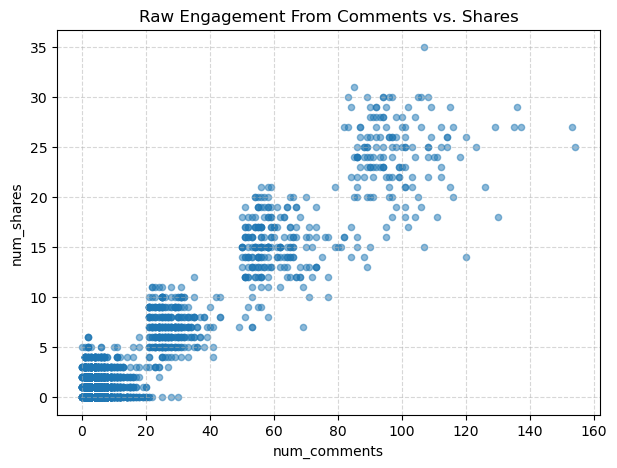

In [5]:
#Step 2.1
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = df_highest_firm[['num_comments', 'num_shares']].copy()
X.plot.scatter(x='num_comments', y='num_shares', alpha=0.5, figsize=(7, 5))
plt.title('Raw Engagement From Comments vs. Shares')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Question 2: 

I observe 4 clusters.

In [6]:
#Step 2.2
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
max_scaled_comments = X_scaled[:, 0].max()
print('Max value of scaled comments:', round(max_scaled_comments,4))

Max value of scaled comments: 4.983


Question 3:

Yes I would expect one variable to dominate a distance-based calculation if left unscaled. The num_comments attribute ranges from 0 to 154, 4 times the amount of num_shares at 0 to 35. So if left unscaled, then the differences in comments will dominate the squared distances. I would probably apply standardization so that both variabls could have a mean of 0 and stadard deviation of 1 so that there's equal weight to comments and shares.

Question 4:

After preprocessing, the max value under the "num_comments" column after preprocessing is 4.983.

In [7]:
#Step 2.3
km = KMeans(n_clusters=4, random_state=42)
km.fit(X_scaled)
df_highest_firm['cluster'] = km.labels_

/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_15100/1009690852.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_highest_firm['cluster'] = km.labels_


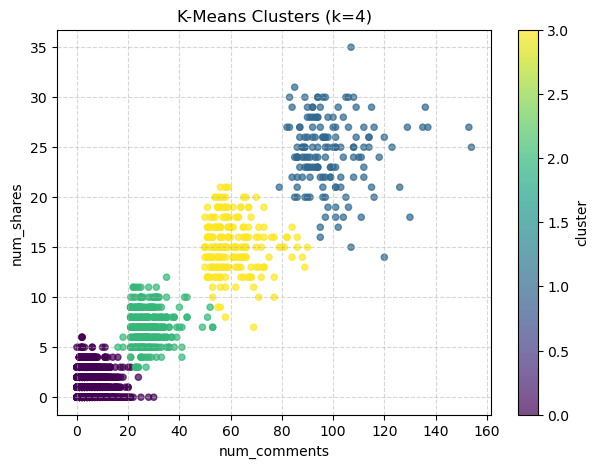

In [8]:
#Step 2.4

df_highest_firm.plot.scatter(x='num_comments',y='num_shares',c='cluster',colormap='viridis',alpha=0.7,figsize=(7, 5),sharex=False)
plt.title('K-Means Clusters (k=4)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Question 6:

I would probably say that the clusters in purple represents daily posts that don't gain much traction and have some comments but not much shares to other accounts. The clusters in green may show a solid base of content in which the community likes to interact. The clusters in yellow show a lot of comments being posted on posts with many accounts sharing the posts. The clusters in blue are a bit more spread but have a lot more reach to accounts and much more interaction from the community.

/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_15100/803250380.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_highest_firm['cluster_run1'] = km_run1.labels_
/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_15100/803250380.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_highest_firm['cluster_run2'] = km_run2.labels_


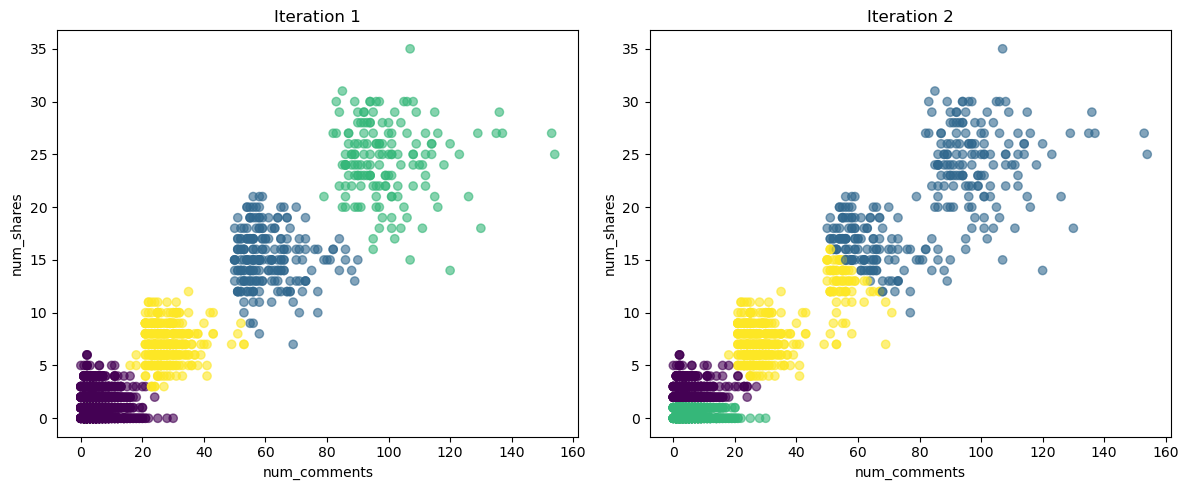

In [11]:
#Step 2.5
km_run1 = KMeans(n_clusters=4, n_init=1, random_state=0).fit(X_scaled)
df_highest_firm['cluster_run1'] = km_run1.labels_

km_run2 = KMeans(n_clusters=4, n_init=1, random_state=65).fit(X_scaled)
df_highest_firm['cluster_run2'] = km_run2.labels_

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

scatter1 = ax1.scatter(df_highest_firm['num_comments'],df_highest_firm['num_shares'],c=df_highest_firm['cluster_run1'],cmap='viridis',alpha=0.6,)
ax1.set_title('Iteration 1')
ax1.set_xlabel('num_comments')
ax1.set_ylabel('num_shares')

scatter2 = ax2.scatter(df_highest_firm['num_comments'],df_highest_firm['num_shares'],c=df_highest_firm['cluster_run2'],cmap='viridis',alpha=0.6,)
ax2.set_title('Iteration 2')
ax2.set_xlabel('num_comments')
ax2.set_ylabel('num_shares')

plt.tight_layout()
plt.show()

Question 7:

There is a sensitivity to the initial centroid placement. Since k-means picks center clusters at random, there are different starting points that can lead the algorithm into picking groupings in which there may be better solutions. But by setting the n_init to 1, ther algorithm would run only one time and leave the results to whatever centroids were first picked. So then to solve this problem n_init is set to 10 at default so that the algorithm is run 10 times with different starting variables and retains the model with the lowest error in total.

In [13]:
#Step 2.6
km_run1 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_scaled)

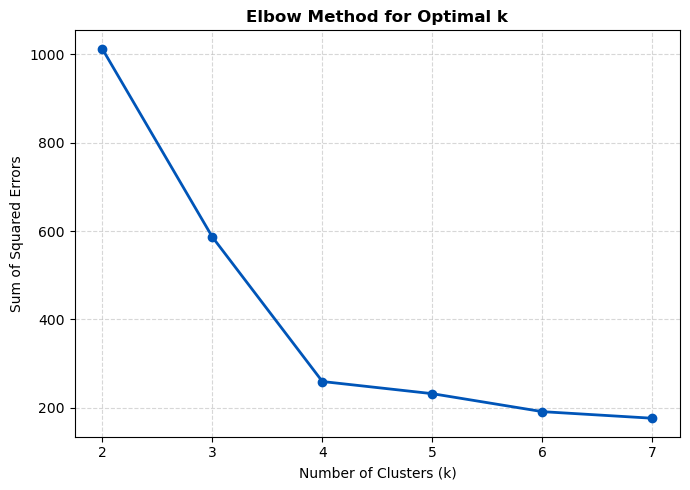

In [14]:
#Step 3.1 and 3.2

sse_list = []
k_range = range(2, 8)

for k in k_range:
  km_model = KMeans(n_clusters=k, random_state=42)
  km_model.fit(X_scaled)
  sse_list.append(km_model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_range),sse_list,marker='o',color='#0055b8',linewidth=2,markersize=6,)
plt.title('Elbow Method for Optimal k', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=10)
plt.ylabel('Sum of Squared Errors', fontsize=10)
plt.xticks(list(k_range))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Question 8:

When looking at the chart, I can see that the ideal k value for this dataset is 4 is the sharp bend happens at 4 and flattens after that.

Step 4.1:

One mistake of that is that the model is being fit on unscaled data. Even though StandardScaler is being used, the k-means model is using the unscaled datafram X instead of X_scaled. Doing this distorts the distance calculations. Another mistake is that the empty list called inertia_values is inside the for loop so that when the loop finishes at k = 7, the inertia_values would only have the inertia value for the last model instead of 6 from k = 2 to 7. 

In [15]:
#Question 9
from sklearn.preprocessing import StandardScaler

X = df[['num_comments', 'num_shares']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

km = KMeans(n_clusters=4, random_state=42)
km.fit(X_scaled)
inertia_values = []

for k in range(2, 8):
  km_k = KMeans(n_clusters=k, random_state=42)
  km_k.fit(X_scaled)
  inertia_values.append(km_k.inertia_)

print('Inertia values for k=2 to 7:', inertia_values)

Inertia values for k=2 to 7: [5545.391233212665, 3152.6261056492335, 2191.0676048823657, 1904.7262856619334, 1270.9456107503086, 966.5189623389056]
